In [81]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [82]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm
from pygraphon.plots.plots_graphon import plot_sample

In [83]:
#recall parameters of experiment
n_min, n_max, n_step =  50, 1001, 50
n_list = np.arange(n_min, n_max, n_step)
rho_n = 10/n_list

k_max = 10
k_list = list(range(2, k_max + 1))

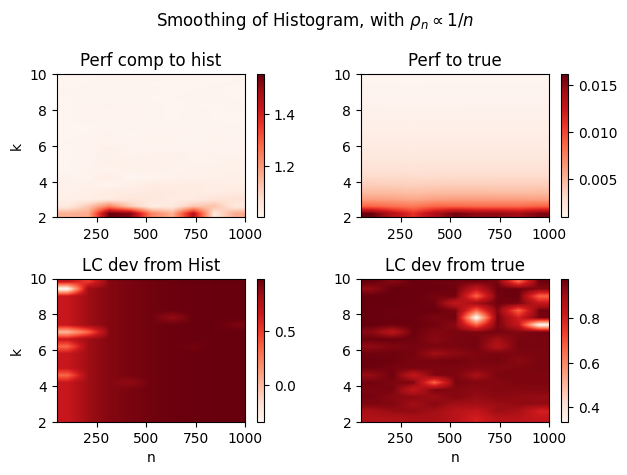

(<Figure size 640x480 with 8 Axes>,
 array([[<AxesSubplot:title={'center':'Perf comp to hist'}, ylabel='k'>,
         <AxesSubplot:title={'center':'Perf to true'}>],
        [<AxesSubplot:title={'center':'LC dev from Hist'}, xlabel='n', ylabel='k'>,
         <AxesSubplot:title={'center':'LC dev from true'}, xlabel='n'>]],
       dtype=object))

In [84]:
import pickle
#Import data
file = open("resultslognn.pkl",'rb')
results = pickle.load(file)
file.close()

#Plots
from experiment_smoothing import smooth_heatmap
from experiment_smoothing import smooth_heatmap2
main_title = r'Smoothing of Histogram, with $\rho_n \propto 1/n$'
subtitle_list = ('Perf comp to hist', 'Perf to true', 'LC dev from Hist',
              'LC dev from true')
tile_type = 'bilinear'
smooth_heatmap2(n_list, k_list, results,main_title, subtitle_list, tile_type)

In [85]:
print(np.min(results[3]))
print(np.argmin(results[3]))
results[3].shape

0.3333333333333333
125


(20, 9)

In [119]:
from gen_sbm import AssociativeFullyRandom
n=90
k=3
#theta init
theta_intra_min, theta_intra_max = 0.3, 0.5
theta_inter_min, theta_inter_max = 0.05, 0.15
theta = AssociativeFullyRandom(
                K=k,
                min_inside_classes=theta_intra_min,
                max_inside_classes=theta_intra_max,
                min_outside_classes=theta_inter_min,
                max_outside_classes=theta_inter_max,
            ).Theta
theta

array([[0.3317348 , 0.07224869, 0.09320896],
       [0.07224869, 0.31060587, 0.09278614],
       [0.09320896, 0.09278614, 0.40477211]])

0.333405694851478
36860.0


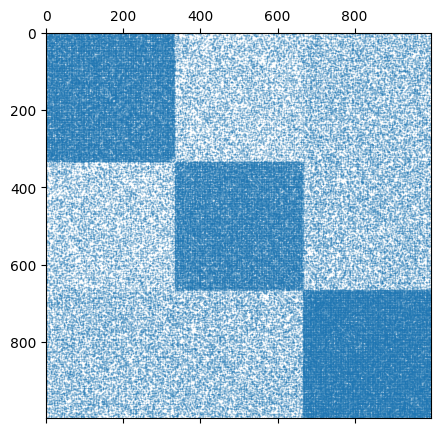

In [210]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
# set up normalised graphon with graphon
n=999
graphon = StepGraphon(theta, 1/k)
# Set Adjacency
A = graphon.draw(rho=1, n=n, exchangeable=False)
spy(A)
print(edge_density(A[0:int(n/3),0:int(n/3)]))
print(np.sum(A[0:int(n/3),0:int(n/3)]))

In [211]:
# Apply histogram anc connectivity matrix
hist = HistogramEstimator(bandwithHist=1/3)
hist.fit(graph=A)
hist_approx = hist.get_graphon()

333
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 2.
 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2.
 2. 1. 2. 1. 2. 2. 2. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 1. 2. 2. 2. 2. 2

In [212]:
hist_approx.graphon*hist_approx.initial_rho
print(edge_density(A))
print(hist_approx.initial_rho)

0.17376294129801143
0.17376294129801143


In [213]:
print(graphon.graphon)
print(hist)

[[1.90944778 0.41585959 0.53650578]
 [0.41585959 1.78783074 0.53407208]
 [0.53650578 0.53407208 2.32984659]]


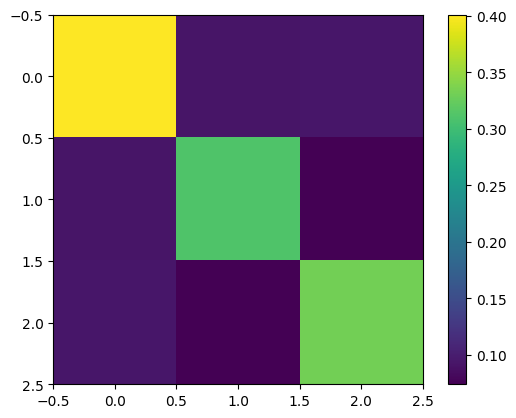

In [214]:
import matplotlib.pyplot as plt
from pygraphon.plots.plots_graphon import plot
plt.imshow(hist_approx.graphon*hist_approx.initial_rho)
plt.colorbar()
plt.show()

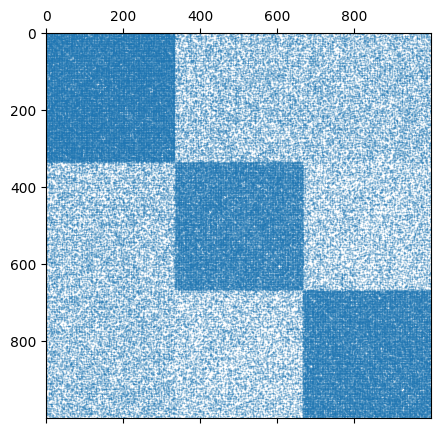

(<Figure size 500x500 with 1 Axes>, <AxesSubplot:>)

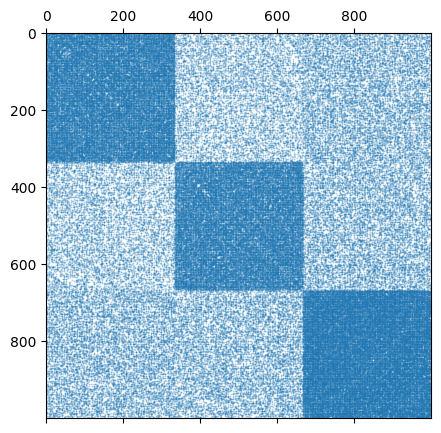

In [215]:
B = hist_approx.draw(rho=1, n=1000, exchangeable=False)
spy(B)
plt.show()
C = graphon.draw(rho=1, n=1000, exchangeable=False)
spy(C)

In [216]:
nrow_tile = hist_approx.graphon.shape[0]
print(nrow_tile)
flat_graphon = hist_approx.graphon[np.triu_indices(nrow_tile)]
print(flat_graphon)
# Clustering according to kmeans
nclust_hist = len(np.unique(flat_graphon))
print(f"number of unique values is {nclust_hist}")

3
[2.30691172 0.53394673 0.53732351 1.79031644 0.42583785 1.90855566]
number of unique values is 6


In [217]:
from sklearn.cluster import KMeans
# copies for different number of clusters
avr_graphon = np.asarray([flat_graphon.copy() for _ in range(nclust_hist)])
for i in range(nclust_hist - 1):
    if i == 0:
        avr_graphon[i] = edge_density(A) * np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i + 1, random_state=0, init="k-means++", n_init=10).fit(
            flat_graphon.reshape(-1, 1)
        )
        # Smooth using mean by memberhsip
        for j in range(i + 1):  # average tiles of same community
            avr_graphon[i][kmeans.labels_ == j] = flat_graphon[kmeans.labels_ == j].mean()

In [218]:
print(flat_graphon)
print(flat_graphon.reshape(-1,1))
avr_graphon[-1]

[2.30691172 0.53394673 0.53732351 1.79031644 0.42583785 1.90855566]
[[2.30691172]
 [0.53394673]
 [0.53732351]
 [1.79031644]
 [0.42583785]
 [1.90855566]]


array([2.30691172, 0.53394673, 0.53732351, 1.79031644, 0.42583785,
       1.90855566])

In [219]:
# Reverse flattening back to 2d
# initiate matrix containing smooth graphon
KM_smooth_g = np.zeros((nclust_hist, nrow_tile, nrow_tile))  # max_k?
i, j = np.triu_indices(nrow_tile)
KM_smooth_g[:, i, j] = avr_graphon
KM_smooth_g[-1]

array([[2.30691172, 0.53394673, 0.53732351],
       [0.        , 1.79031644, 0.42583785],
       [0.        , 0.        , 1.90855566]])

In [220]:
# Make it symmetric by extracting diag, making it 3d and doing X+X^T-diag(X)
# Extract diagonal
i, j = np.diag_indices(nrow_tile)
diag_km_vec = np.diagonal(KM_smooth_g, axis1=1, axis2=2)
# make 3d array with diagonal in axis 1&2
diag_km = np.zeros((nclust_hist, nrow_tile, nrow_tile))  # max_k ?
diag_km[:, i, j] = diag_km_vec
# X+X^T-diag(X) on axis (1,2) of tensor
sym_KM_smooth_g = KM_smooth_g + np.transpose(KM_smooth_g, (0, 2, 1)) - diag_km
sym_KM_smooth_g[-1]

array([[2.30691172, 0.53394673, 0.53732351],
       [0.53394673, 1.79031644, 0.42583785],
       [0.53732351, 0.42583785, 1.90855566]])

In [221]:
# Get smooth graphon into correct form and \hat{pij} for the whole tensor
smoothed_graphons = [
    StepGraphon(
        graphon=sym_KM_smooth_g[i],
        bandwidthHist=hist_approx.bandwidthHist,
        initial_rho=hist_approx.initial_rho,
    )
    for i in range(sym_KM_smooth_g.shape[0])
]
P_smooth = np.array(
    [g._get_edge_probabilities(n=n, exchangeable=False) for g in smoothed_graphons]
)

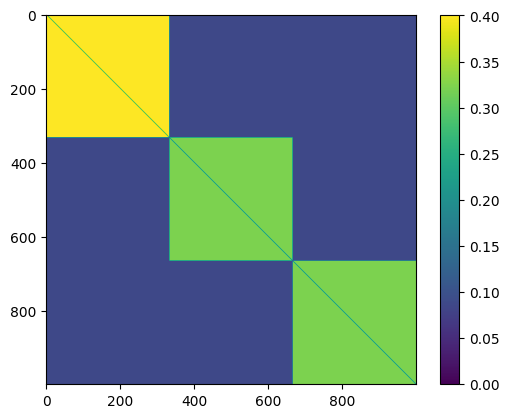

In [222]:
import matplotlib.pyplot as plt
from pygraphon.plots.plots_graphon import plot
plt.imshow(P_smooth[2])
plt.colorbar()

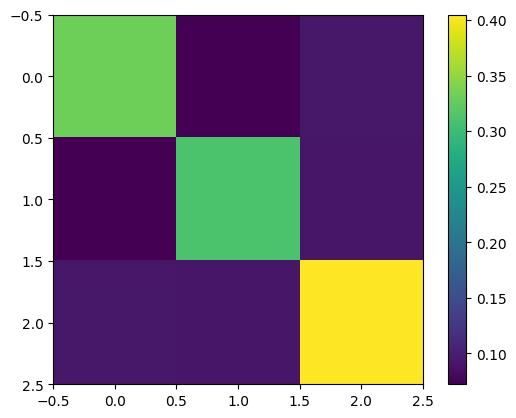

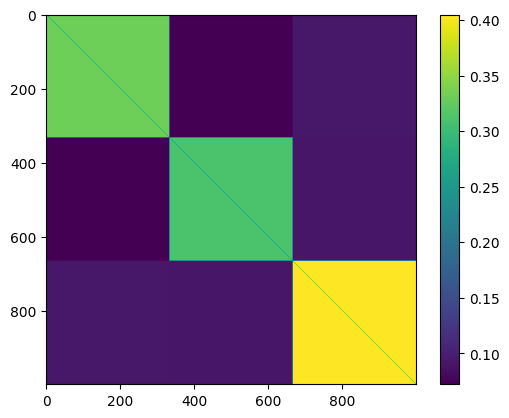

In [223]:
P_star_test  = graphon._get_edge_probabilities(n=n,exchangeable= False,wholeMatrix=True)
for i in range(P_star_test.shape[0]):
    P_star_test[i,i] = 0.2
plt.imshow(graphon.graphon*graphon.initial_rho)
plt.colorbar()
plt.show()
plt.imshow(P_star_test)
plt.colorbar()
plt.show()

In [224]:
# Compute error, MSE
print(P_smooth[0].shape[0]==n)
print(P_smooth.shape[1]==n)
smoothed_graphons_error = np.zeros(P_smooth.shape[0])
P_star = graphon._get_edge_probabilities(P_smooth[0].shape[0], exchangeable= False, wholeMatrix=True)  # theoretical P
for i in range(P_smooth.shape[0]):
    smoothed_graphons_error[i] = np.linalg.norm((P_smooth[i]-P_star))**2 / (
        P_smooth.shape[1]**2
    )

True
True


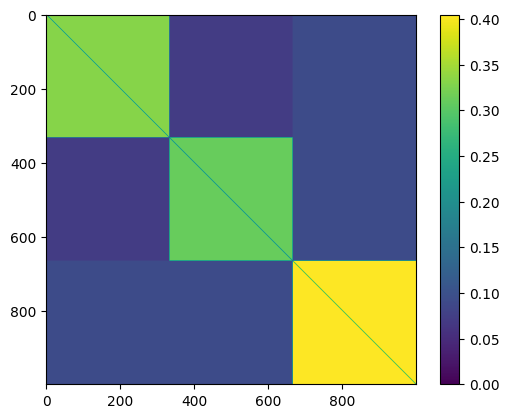

In [225]:
plt.imshow(P_star)
plt.colorbar()

error is min when lc=2
[0.01593973 0.00060542 0.00137683 0.00148761 0.00129667 0.00129397]
0.015668721926527705


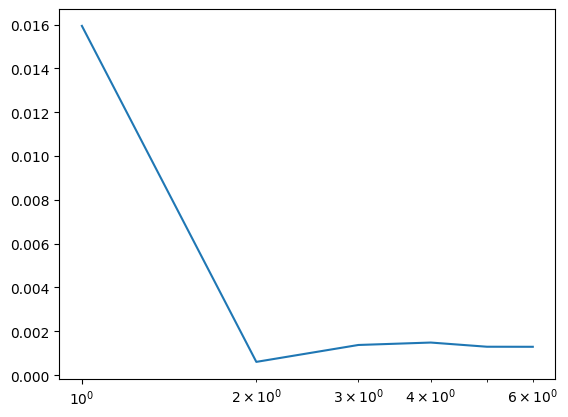

In [226]:
print(f"error is min when lc={1+np.argmin(smoothed_graphons_error)}")
plt.plot(np.arange(1,nclust_hist+1),smoothed_graphons_error)
plt.xscale('log')
print(smoothed_graphons_error)
print((np.linalg.norm(P_smooth[0] - P_smooth[-1])**2 )/n**2)


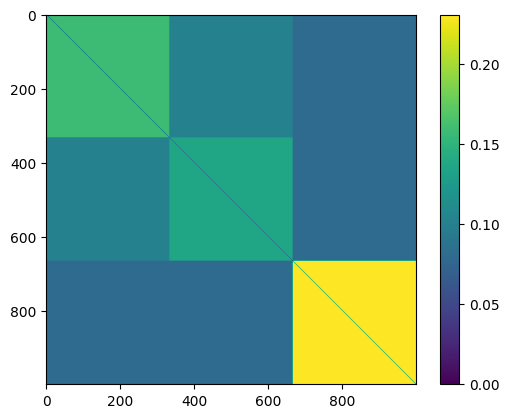

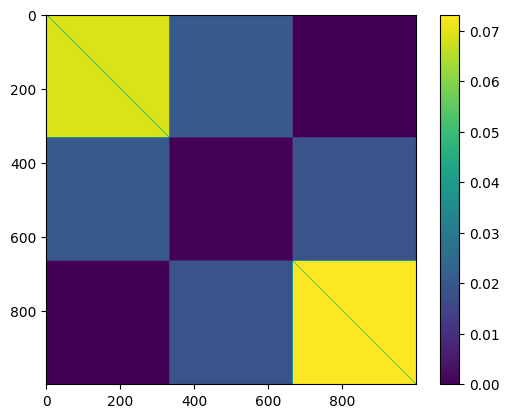

(<Figure size 500x500 with 1 Axes>, <AxesSubplot:>)

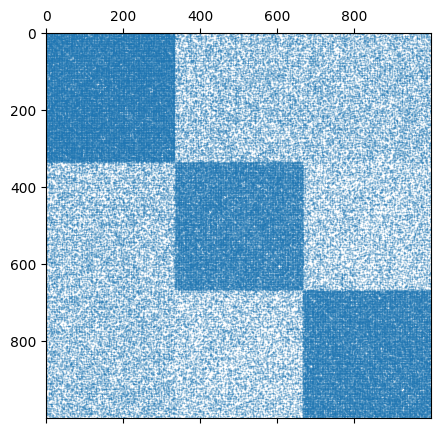

In [227]:
plt.imshow(np.abs(P_smooth[0]-P_star))
plt.colorbar()
plt.show()
plt.imshow(np.abs(P_smooth[-1]-P_star))
plt.colorbar()
plt.show()
spy(B)